# Milestone 2: CLIP + GPT-2 Integration, Baseline Captioning & Decoding Strategies

**Continues from:** Milestone 1 (`milestone1_output/`: CLIP ViT-B/32 embeddings, GPT-2 tokenized captions, metadata)
**Tasks covered:**
1. Integrate the CLIP image encoder with the GPT-2 decoder through **prefix conditioning** (ClipCap style MLP mapper). A **cross-attention** variant is also implemented and can be switched on in `CONFIG`.
2. Run baseline caption generation on held-out sample images and record the first set of generated captions (before training and after every epoch).
3. Compare decoding strategies: greedy, beam search (k=3, k=5) and nucleus sampling (p=0.9, T=0.7 and T=1.0).

**Outputs (in `milestone2_output/`):** `training_log.txt`, `step_log.csv`, `epoch_log.csv`, `caption_history.json`, `sample_captions.csv`, `decoding_metrics.csv`, plots, and the submission report `Milestone2_Report.docx` (front page + training log + caption samples + summary of observations).

> Tip: set `QUICK_RUN = True` in the config cell for a 1 epoch smoke test before the full run.

## 1. Environment Setup

In [2]:
%pip install -q torch torchvision transformers datasets pillow matplotlib pandas requests pycocoevalcap python-docx

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, json, time, math, random, re, datetime, textwrap
from collections import Counter
from io import BytesIO

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import requests
from PIL import Image
from transformers import GPT2Tokenizer, GPT2LMHeadModel, CLIPModel, CLIPProcessor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")   # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")
print(f"Device: {DEVICE}")

M1_DIR = "/kaggle/input/notebooks/reshmasrig/milestone-1/milestone1_output"
OUT_DIR = "milestone2_output"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "samples"), exist_ok=True)

CONFIG = {
    "injection": "prefix",       # "prefix" (visual tokens prepended to GPT-2 input) or "cross_attention"
    "prefix_length": 10,          # number of visual tokens the mapper produces
    "finetune_gpt2": True,        # False: GPT-2 frozen, only the mapper (and cross attention layers) train
    "epochs": 5,
    "batch_size": 32,
    "lr_mapper": 2e-4,
    "lr_gpt2": 3e-5,
    "weight_decay": 0.01,
    "warmup_steps": 300,
    "grad_clip": 1.0,
    "max_caption_tokens": 40,
    "val_fraction": 0.10,
    "log_every": 50,
    "num_sample_images": 8,
    "eval_images": 200,
    "max_gen_tokens": 30,
    "save_checkpoint": True,
}
QUICK_RUN = False   # True: 1 epoch on 20% of the training captions to smoke test everything end to end
if QUICK_RUN:
    CONFIG.update(epochs=1, eval_images=50, warmup_steps=50)

LOG_PATH = os.path.join(OUT_DIR, "training_log.txt")
open(LOG_PATH, "w").close()

def log(msg=""):
    print(msg)
    with open(LOG_PATH, "a") as f:
        f.write(msg + "\n")

log(f"Run started {datetime.datetime.now():%Y-%m-%d %H:%M:%S} on {DEVICE}")
log("Config: " + json.dumps(CONFIG))

Device: cuda
Run started 2026-11-18 19:51:11 on cuda
Config: {"injection": "prefix", "prefix_length": 10, "finetune_gpt2": true, "epochs": 5, "batch_size": 32, "lr_mapper": 0.0002, "lr_gpt2": 3e-05, "weight_decay": 0.01, "warmup_steps": 300, "grad_clip": 1.0, "max_caption_tokens": 40, "val_fraction": 0.1, "log_every": 50, "num_sample_images": 8, "eval_images": 200, "max_gen_tokens": 30, "save_checkpoint": true}


## 2. Load Milestone 1 Artifacts

In [4]:
def safe_torch_load(path):
    try:
        return torch.load(path)
    except Exception:
        return torch.load(path, weights_only=False)

for fname in ["clip_embeddings.pt", "tokenized_captions.pt", "metadata.json"]:
    path = os.path.join(M1_DIR, fname)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found. Run the Milestone 1 notebook first (it writes {M1_DIR}/) "
                                f"or set M1_DIR to the folder that holds it.")

clip_embeddings = safe_torch_load(os.path.join(M1_DIR, "clip_embeddings.pt")).float()
tok_data = safe_torch_load(os.path.join(M1_DIR, "tokenized_captions.pt"))
with open(os.path.join(M1_DIR, "metadata.json")) as f:
    metadata = json.load(f)

raw_captions = list(tok_data["raw_captions"])
caption_to_image = [int(i) for i in tok_data["caption_to_image"]]
NUM_IMAGES, CLIP_DIM = clip_embeddings.shape

image_to_captions = {}
for ci, img in enumerate(caption_to_image):
    image_to_captions.setdefault(img, []).append(raw_captions[ci])

log(f"Loaded {NUM_IMAGES} CLIP embeddings (dim {CLIP_DIM}), {len(raw_captions)} captions")
log(f"Embedding norm check: {clip_embeddings.norm(dim=-1).mean():.4f}")

Loaded 5000 CLIP embeddings (dim 512), 25013 captions
Embedding norm check: 1.0000


## 3. Recover Image URLs (for displaying sample images)
Milestone 1 sampled its 5K subset with `random.sample` right after `random.seed(42)`, so the same indices can be regenerated. The cell verifies the alignment against the saved captions before using any image. If the check fails, training and evaluation still run (they only need the saved embeddings); only the image thumbnails are skipped.

In [5]:
from datasets import load_dataset

def clean_caption(caption):   # identical to Milestone 1
    caption = caption.lower().strip()
    caption = re.sub(r'\s+', ' ', caption)
    caption = re.sub(r'[^a-z0-9\s.,!?\'\-]', '', caption)
    caption = caption.strip(' .,!?')
    return caption

full_dataset = load_dataset("yerevann/coco-karpathy", split="train")
subset_indices = random.Random(SEED).sample(range(len(full_dataset)), metadata["num_images"])
subset = full_dataset.select(subset_indices)

check_n = min(200, NUM_IMAGES)
matches = 0
for i in range(check_n):
    cleaned = [clean_caption(c) for c in subset[i]["sentences"]]
    cleaned = [c for c in cleaned if 5 <= len(c.split()) <= 50]
    matches += int(cleaned == image_to_captions.get(i, []))

IMAGES_ALIGNED = (matches == check_n)
image_urls = list(subset["url"]) if IMAGES_ALIGNED else None
log(f"Image alignment check: {matches}/{check_n} match -> images {'available' if IMAGES_ALIGNED else 'NOT available (captions only)'}")

README.md:   0%|          | 0.00/246 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.0MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

... (4 outputs left out)

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating restval split:   0%|          | 0/30504 [00:00<?, ? examples/s]

Image alignment check: 200/200 match -> images available


## 4. Train / Validation Split and Caption Dataset

In [6]:
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
EOS_ID = tokenizer.eos_token_id

# Split by IMAGE so no validation image (or any of its captions) is seen in training
perm = np.random.RandomState(SEED).permutation(NUM_IMAGES)
n_val = int(round(NUM_IMAGES * CONFIG["val_fraction"]))
val_image_ids = sorted(perm[:n_val].tolist())
train_image_ids = sorted(perm[n_val:].tolist())
val_set = set(val_image_ids)

train_caption_idx = [ci for ci, img in enumerate(caption_to_image) if img not in val_set]
val_caption_idx = [ci for ci, img in enumerate(caption_to_image) if img in val_set]
if QUICK_RUN:
    train_caption_idx = random.Random(SEED).sample(train_caption_idx, len(train_caption_idx) // 5)

class CaptionDataset(Dataset):
    # Each item: (CLIP embedding of the image, caption token ids ending in <|endoftext|>)
    def __init__(self, caption_indices, max_tokens):
        self.items = []
        for ci in caption_indices:
            ids = tokenizer.encode(raw_captions[ci])[: max_tokens - 1] + [EOS_ID]
            self.items.append((caption_to_image[ci], ids))
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        img, ids = self.items[i]
        return clip_embeddings[img], torch.tensor(ids, dtype=torch.long)

def collate(batch):
    embs = torch.stack([b[0] for b in batch])
    max_len = max(len(b[1]) for b in batch)
    input_ids = torch.full((len(batch), max_len), EOS_ID, dtype=torch.long)
    attn = torch.zeros((len(batch), max_len), dtype=torch.long)
    labels = torch.full((len(batch), max_len), -100, dtype=torch.long)   # -100 = ignored by the loss
    for i, (_, ids) in enumerate(batch):
        n = len(ids)
        input_ids[i, :n] = ids
        attn[i, :n] = 1
        labels[i, :n] = ids
    return embs, input_ids, attn, labels

train_ds = CaptionDataset(train_caption_idx, CONFIG["max_caption_tokens"])
val_ds = CaptionDataset(val_caption_idx, CONFIG["max_caption_tokens"])
train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True, collate_fn=collate,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=CONFIG["batch_size"], shuffle=False, collate_fn=collate)

log(f"Train: {len(train_image_ids)} images / {len(train_ds)} captions / {len(train_loader)} batches")
log(f"Val:   {len(val_image_ids)} images / {len(val_ds)} captions / {len(val_loader)} batches")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Train: 4500 images / 22512 captions / 704 batches
Val:   500 images / 2501 captions / 79 batches


## 5. Model: CLIP Embedding → Mapper → GPT-2

**Prefix conditioning (default).** The frozen CLIP ViT-B/32 embedding (512-d, precomputed in Milestone 1) goes through an MLP mapper that outputs `prefix_length` vectors of size 768 (GPT-2's embedding size). These visual tokens are prepended to the caption's token embeddings, so GPT-2's causal self-attention lets every caption token attend to the image. The loss is computed only on caption tokens.

**Cross-attention (optional, `CONFIG["injection"] = "cross_attention"`).** GPT-2 is loaded with `add_cross_attention=True`, which inserts a newly initialized cross-attention block into each of the 12 layers; the mapper's visual tokens are passed as `encoder_hidden_states`, and the caption starts from a `<|endoftext|>` BOS token.

In [7]:
class MLPMapper(nn.Module):
    # ClipCap MLP mapper: 512 -> (768*P)/2 -> 768*P, reshaped to P visual tokens
    def __init__(self, clip_dim, gpt_dim, prefix_length):
        super().__init__()
        self.prefix_length, self.gpt_dim = prefix_length, gpt_dim
        hidden = (gpt_dim * prefix_length) // 2
        self.net = nn.Sequential(
            nn.Linear(clip_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, gpt_dim * prefix_length),
        )
    def forward(self, x):
        return self.net(x).view(x.shape[0], self.prefix_length, self.gpt_dim)


class ClipGPT2Captioner(nn.Module):
    def __init__(self, clip_dim, injection="prefix", prefix_length=10, finetune_gpt2=True):
        super().__init__()
        assert injection in ("prefix", "cross_attention")
        self.injection = injection
        self.prefix_length = prefix_length
        if injection == "cross_attention":
            self.gpt = GPT2LMHeadModel.from_pretrained("gpt2", add_cross_attention=True)
        else:
            self.gpt = GPT2LMHeadModel.from_pretrained("gpt2")
        self.gpt_dim = self.gpt.config.n_embd
        self.mapper = MLPMapper(clip_dim, self.gpt_dim, prefix_length)
        if not finetune_gpt2:
            for name, p in self.gpt.named_parameters():
                p.requires_grad = ("crossattention" in name) or ("ln_cross_attn" in name)

    def visual_tokens(self, clip_emb):
        return self.mapper(clip_emb)                      # (B, P, 768)

    def _wte(self, ids):
        return self.gpt.transformer.wte(ids)

    def forward(self, clip_emb, input_ids, attention_mask, labels):
        vis = self.visual_tokens(clip_emb)
        B, dev = input_ids.shape[0], input_ids.device
        if self.injection == "prefix":
            embeds = torch.cat([vis, self._wte(input_ids)], dim=1)
            mask = torch.cat([torch.ones(B, self.prefix_length, dtype=attention_mask.dtype, device=dev), attention_mask], 1)
            full_labels = torch.cat([torch.full((B, self.prefix_length), -100, dtype=labels.dtype, device=dev), labels], 1)
            out = self.gpt(inputs_embeds=embeds, attention_mask=mask, labels=full_labels)
        else:
            bos = torch.full((B, 1), EOS_ID, dtype=input_ids.dtype, device=dev)
            ids = torch.cat([bos, input_ids], 1)
            mask = torch.cat([torch.ones(B, 1, dtype=attention_mask.dtype, device=dev), attention_mask], 1)
            full_labels = torch.cat([torch.full((B, 1), -100, dtype=labels.dtype, device=dev), labels], 1)
            out = self.gpt(input_ids=ids, attention_mask=mask, labels=full_labels, encoder_hidden_states=vis)
        return out.loss

    @torch.no_grad()
    def next_token_logits(self, vis, gen_ids):
        # Logits for the next token given visual tokens (B, P, 768) and generated ids so far (B, t)
        if self.injection == "prefix":
            embeds = vis if gen_ids.shape[1] == 0 else torch.cat([vis, self._wte(gen_ids)], 1)
            logits = self.gpt(inputs_embeds=embeds).logits
        else:
            bos = torch.full((gen_ids.shape[0], 1), EOS_ID, dtype=torch.long, device=gen_ids.device)
            logits = self.gpt(input_ids=torch.cat([bos, gen_ids], 1), encoder_hidden_states=vis).logits
        return logits[:, -1, :].float()


model = ClipGPT2Captioner(CLIP_DIM, CONFIG["injection"], CONFIG["prefix_length"], CONFIG["finetune_gpt2"]).to(DEVICE)

def n_params(params):
    return sum(p.numel() for p in params)

PARAMS = {
    "mapper": n_params(model.mapper.parameters()),
    "gpt2": n_params(model.gpt.parameters()),
    "trainable": n_params(p for p in model.parameters() if p.requires_grad),
    "mapper_hidden": model.mapper.net[0].out_features,
}
log(f"Injection: {CONFIG['injection']} | prefix length {CONFIG['prefix_length']} | GPT-2 fine-tuned: {CONFIG['finetune_gpt2']}")
log(f"Params: mapper {PARAMS['mapper']/1e6:.1f}M | GPT-2 {PARAMS['gpt2']/1e6:.1f}M | trainable {PARAMS['trainable']/1e6:.1f}M")

# Shape / loss sanity check on one batch
embs, ids, attn, labels = next(iter(train_loader))
with torch.no_grad():
    l0 = model(embs.to(DEVICE), ids.to(DEVICE), attn.to(DEVICE), labels.to(DEVICE))
log(f"Sanity batch: clip {tuple(embs.shape)} -> visual tokens {tuple(model.visual_tokens(embs[:2].to(DEVICE)).shape)} | "
    f"captions {tuple(ids.shape)} | initial loss {l0.item():.3f}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Injection: prefix | prefix length 10 | GPT-2 fine-tuned: True
Params: mapper 31.5M | GPT-2 124.4M | trainable 155.9M


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Sanity batch: clip (32, 512) -> visual tokens (2, 10, 768) | captions (32, 24) | initial loss 9.603


## 6. Decoding Strategies
All three decoders are written by hand on top of `next_token_logits`, so the exact same model and visual prefix are used for each, and the behaviour does not depend on `generate()` internals.
* **Greedy:** take the arg max token at every step.
* **Beam search:** keep the `k` highest scoring partial captions; finished hypotheses are ranked by log probability / length^α (α = 0.7).
* **Nucleus (top p) sampling:** sample from the smallest set of tokens whose cumulative probability exceeds `p`, after temperature scaling.

In [8]:
def ids_to_text(ids):
    if EOS_ID in ids:
        ids = ids[: ids.index(EOS_ID)]
    return tokenizer.decode(ids, skip_special_tokens=True).strip()

@torch.no_grad()
def greedy_decode(model, clip_embs, max_len=30):
    model.eval()
    vis = model.visual_tokens(clip_embs.to(DEVICE))
    B = vis.shape[0]
    gen = torch.empty((B, 0), dtype=torch.long, device=DEVICE)
    done = torch.zeros(B, dtype=torch.bool, device=DEVICE)
    for _ in range(max_len):
        nxt = model.next_token_logits(vis, gen).argmax(-1)
        nxt = torch.where(done, torch.full_like(nxt, EOS_ID), nxt)
        gen = torch.cat([gen, nxt[:, None]], 1)
        done |= (nxt == EOS_ID)
        if done.all():
            break
    return [ids_to_text(row) for row in gen.tolist()]

@torch.no_grad()
def nucleus_decode(model, clip_embs, max_len=30, top_p=0.9, temperature=0.7, seed=SEED):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    vis = model.visual_tokens(clip_embs.to(DEVICE))
    B = vis.shape[0]
    gen = torch.empty((B, 0), dtype=torch.long, device=DEVICE)
    done = torch.zeros(B, dtype=torch.bool, device=DEVICE)
    for _ in range(max_len):
        probs = F.softmax(model.next_token_logits(vis, gen) / temperature, dim=-1).cpu()
        sorted_p, sorted_i = probs.sort(dim=-1, descending=True)
        cum = sorted_p.cumsum(-1)
        sorted_p[(cum - sorted_p) > top_p] = 0.0          # drop tokens outside the nucleus
        sorted_p = sorted_p / sorted_p.sum(-1, keepdim=True)
        choice = torch.multinomial(sorted_p, 1, generator=g)
        nxt = sorted_i.gather(-1, choice).squeeze(-1).to(DEVICE)
        nxt = torch.where(done, torch.full_like(nxt, EOS_ID), nxt)
        gen = torch.cat([gen, nxt[:, None]], 1)
        done |= (nxt == EOS_ID)
        if done.all():
            break
    return [ids_to_text(row) for row in gen.tolist()]

@torch.no_grad()
def beam_decode(model, clip_embs, beam_size=5, max_len=30, length_alpha=0.7):
    model.eval()
    results = []
    for e in clip_embs:
        vis = model.visual_tokens(e.unsqueeze(0).to(DEVICE))
        beams = [(0.0, [])]
        finished = []
        for step in range(max_len):
            if step == 0:
                gen = torch.empty((1, 0), dtype=torch.long, device=DEVICE)
            else:
                gen = torch.tensor([s for _, s in beams], dtype=torch.long, device=DEVICE)
            logp = F.log_softmax(model.next_token_logits(vis.expand(gen.shape[0], -1, -1), gen), dim=-1)
            top_v, top_i = logp.topk(beam_size, dim=-1)
            candidates = []
            for b, (score, seq) in enumerate(beams):
                for v, i in zip(top_v[b].tolist(), top_i[b].tolist()):
                    candidates.append((score + v, seq + [i]))
            candidates.sort(key=lambda x: x[0], reverse=True)
            beams = []
            for score, seq in candidates:
                if seq[-1] == EOS_ID:
                    finished.append((score / (len(seq) ** length_alpha), seq))
                else:
                    beams.append((score, seq))
                if len(beams) == beam_size:
                    break
            if len(finished) >= beam_size or not beams:
                break
        if not finished:
            finished = [(s / (len(q) ** length_alpha), q) for s, q in beams]
        best = max(finished, key=lambda x: x[0])[1]
        results.append(ids_to_text(best))
    return results

L = CONFIG["max_gen_tokens"]
STRATEGIES = {
    "Greedy":                 lambda m, e: greedy_decode(m, e, L),
    "Beam (k=3)":             lambda m, e: beam_decode(m, e, 3, L),
    "Beam (k=5)":             lambda m, e: beam_decode(m, e, 5, L),
    "Nucleus (p=0.9, T=0.7)": lambda m, e: nucleus_decode(m, e, L, 0.9, 0.7),
    "Nucleus (p=0.9, T=1.0)": lambda m, e: nucleus_decode(m, e, L, 0.9, 1.0),
}

## 7. Sample Images (held-out validation images)

In [9]:
SAMPLE_IDS = sorted(random.Random(SEED + 1).sample(val_image_ids, CONFIG["num_sample_images"]))
sample_embs = clip_embeddings[SAMPLE_IDS]

def download_image(url):
    try:
        r = requests.get(url, timeout=15)
        return Image.open(BytesIO(r.content)).convert("RGB")
    except Exception:
        return None

sample_images = {i: (download_image(image_urls[i]) if IMAGES_ALIGNED else None) for i in SAMPLE_IDS}
for i in SAMPLE_IDS:
    img = sample_images[i]
    if img is not None:
        thumb = img.copy()
        thumb.thumbnail((420, 420))
        thumb.save(os.path.join(OUT_DIR, "samples", f"img_{i}.jpg"), quality=90)
log(f"Sample image ids: {SAMPLE_IDS} | downloaded {sum(v is not None for v in sample_images.values())}/{len(SAMPLE_IDS)}")

Sample image ids: [149, 599, 1293, 1670, 2223, 3382, 3773, 4866] | downloaded 8/8


## 8. Baseline Caption Generation (before training)

In [10]:
@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    total, n = 0.0, 0
    for embs, ids, attn, labels in loader:
        loss = model(embs.to(DEVICE), ids.to(DEVICE), attn.to(DEVICE), labels.to(DEVICE))
        tokens = int((labels != -100).sum())
        total += loss.item() * tokens
        n += tokens
    return total / n

caption_history = {}   # epoch -> {image_id: greedy caption}
epoch_rows, step_rows = [], []

base_val = evaluate_loss(model, val_loader)
caption_history[0] = dict(zip(SAMPLE_IDS, greedy_decode(model, sample_embs, L)))
epoch_rows.append({"epoch": 0, "train_loss": float("nan"), "val_loss": base_val,
                   "val_ppl": math.exp(base_val), "epoch_time_s": 0.0})

log("=" * 90)
log(f"BASELINE (epoch 0, untrained mapper) | val loss {base_val:.4f} | val ppl {math.exp(base_val):.1f}")
for i in SAMPLE_IDS:
    log(f"  [img {i}] GEN: {caption_history[0][i]}")
    log(f"  [img {i}] REF: {image_to_captions[i][0]}")
log("=" * 90)

BASELINE (epoch 0, untrained mapper) | val loss 9.8386 | val ppl 18742.7
  [img 149] GEN: be a "t-1-in-the-game" (t-1-in-the-game) for the first time.
  [img 149] REF: a fully stocked refrigerator with the door wide open
  [img 599] GEN: (1) the "A-1-1-1-1-1-1-1-1-1-1-1-1
  [img 599] REF: large group of people sitting in a room working on their computers
  [img 1293] GEN: (1) the "A-1-1-1-1-1-1-1-1-1-1-1-1
  [img 1293] REF: an extremely large hamburger with a salad and fried on a table
  [img 1670] GEN: be the first-in-name-of-the-name-of-the-name-of-the-name-of-the-
  [img 1670] REF: a bunch of people walk along with an elephant on a street
  [img 2223] GEN: (1) the "M-1-1-1-1-1-1-1-1-1-1-1-1
  [img 2223] REF: a group of people getting on to a bus
  [img 3382] GEN: be a "t-1-in-the-game" (t-1-in-the-game) (t-1-in
  [img 3382] REF: two dogs stand in a kitchen beneath their owner
  [img 3773] GEN: (1) the "M-1-1-1-1-1-1-1-1-1-1-1-1
  [img 3773] REF: a person is playing a tennis game by 

## 9. Training 

In [11]:
mapper_params = list(model.mapper.parameters())
other_params = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("mapper.")]
param_groups = [{"params": mapper_params, "lr": CONFIG["lr_mapper"]}]
if other_params:
    param_groups.append({"params": other_params, "lr": CONFIG["lr_gpt2"]})
optimizer = torch.optim.AdamW(param_groups, weight_decay=CONFIG["weight_decay"])

total_steps = CONFIG["epochs"] * len(train_loader)
warmup = min(CONFIG["warmup_steps"], max(1, total_steps // 10))
def lr_lambda(step):
    if step < warmup:
        return (step + 1) / warmup
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
CKPT_PATH = os.path.join(OUT_DIR, "best_model.pt")

global_step, best_val, best_epoch = 0, float("inf"), 0
run_start = time.time()
for epoch in range(1, CONFIG["epochs"] + 1):
    model.train()
    t0 = time.time()
    win_loss, win_n, ep_loss, ep_n = 0.0, 0, 0.0, 0
    for step, (embs, ids, attn, labels) in enumerate(train_loader, 1):
        embs, ids, attn, labels = embs.to(DEVICE), ids.to(DEVICE), attn.to(DEVICE), labels.to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            loss = model(embs, ids, attn, labels)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], CONFIG["grad_clip"])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        global_step += 1
        li = loss.item()
        win_loss, win_n, ep_loss, ep_n = win_loss + li, win_n + 1, ep_loss + li, ep_n + 1
        if step % CONFIG["log_every"] == 0 or step == len(train_loader):
            avg = win_loss / win_n
            lr_now = scheduler.get_last_lr()[-1]
            step_rows.append({"epoch": epoch, "step": step, "global_step": global_step, "train_loss": avg,
                              "lr": lr_now, "elapsed_s": time.time() - run_start})
            log(f"epoch {epoch} | step {step:4d}/{len(train_loader)} | loss {avg:.4f} | lr {lr_now:.2e} | {time.time() - t0:.0f}s")
            win_loss, win_n = 0.0, 0

    train_loss = ep_loss / ep_n
    val_loss = evaluate_loss(model, val_loader)
    caption_history[epoch] = dict(zip(SAMPLE_IDS, greedy_decode(model, sample_embs, L)))
    ep_time = time.time() - t0
    epoch_rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                       "val_ppl": math.exp(val_loss), "epoch_time_s": ep_time})
    log("-" * 90)
    log(f"EPOCH {epoch} DONE | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val ppl {math.exp(val_loss):.2f} | {ep_time:.0f}s")
    for i in SAMPLE_IDS[:3]:
        log(f"  [img {i}] {caption_history[epoch][i]}")
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch
        if CONFIG["save_checkpoint"]:
            torch.save({"model": model.state_dict(), "config": CONFIG, "epoch": epoch}, CKPT_PATH)
            log(f"  new best val loss, checkpoint saved to {CKPT_PATH}")
    log("-" * 90)

log(f"Training finished in {(time.time() - run_start) / 60:.1f} min | best epoch {best_epoch} (val loss {best_val:.4f})")

if CONFIG["save_checkpoint"] and os.path.exists(CKPT_PATH):
    model.load_state_dict(safe_torch_load(CKPT_PATH)["model"])
    log(f"Reloaded best checkpoint (epoch {best_epoch}) for decoding experiments")

epoch_df = pd.DataFrame(epoch_rows)
step_df = pd.DataFrame(step_rows)
epoch_df.to_csv(os.path.join(OUT_DIR, "epoch_log.csv"), index=False)
step_df.to_csv(os.path.join(OUT_DIR, "step_log.csv"), index=False)
with open(os.path.join(OUT_DIR, "caption_history.json"), "w") as f:
    json.dump({str(k): {str(i): c for i, c in v.items()} for k, v in caption_history.items()}, f, indent=2)
epoch_df

/tmp/ipykernel_49/521857579.py:36: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1 | step   50/704 | loss 5.6508 | lr 5.10e-06 | 8s
epoch 1 | step  100/704 | loss 3.3707 | lr 1.01e-05 | 16s
epoch 1 | step  150/704 | loss 3.0833 | lr 1.51e-05 | 24s
epoch 1 | step  200/704 | loss 2.8580 | lr 2.01e-05 | 32s
epoch 1 | step  250/704 | loss 2.7676 | lr 2.51e-05 | 41s
epoch 1 | step  300/704 | loss 2.6815 | lr 3.00e-05 | 49s
epoch 1 | step  350/704 | loss 2.6460 | lr 2.95e-05 | 57s
epoch 1 | step  400/704 | loss 2.5930 | lr 2.91e-05 | 65s
epoch 1 | step  450/704 | loss 2.5671 | lr 2.86e-05 | 73s
epoch 1 | step  500/704 | loss 2.5458 | lr 2.81e-05 | 81s
epoch 1 | step  550/704 | loss 2.5880 | lr 2.77e-05 | 89s
epoch 1 | step  600/704 | loss 2.4898 | lr 2.72e-05 | 98s
epoch 1 | step  650/704 | loss 2.4936 | lr 2.67e-05 | 106s
epoch 1 | step  700/704 | loss 2.4516 | lr 2.63e-05 | 114s
epoch 1 | step  704/704 | loss 2.4975 | lr 2.62e-05 | 115s
------------------------------------------------------------------------------------------
EPOCH 1 DONE | train loss 2.9110 | va

,epoch,train_loss,val_loss,val_ppl,epoch_time_s
0,0,NaN,9.838560,18742.704546,0.000000
1,1,2.910974,2.453355,11.627289,121.242402
2,2,2.310455,2.371851,10.717215,123.675868
3,3,2.136402,2.360877,10.600240,123.703750
4,4,2.014662,2.355478,10.543165,124.022346
5,5,1.923050,2.372756,10.726914,123.806458


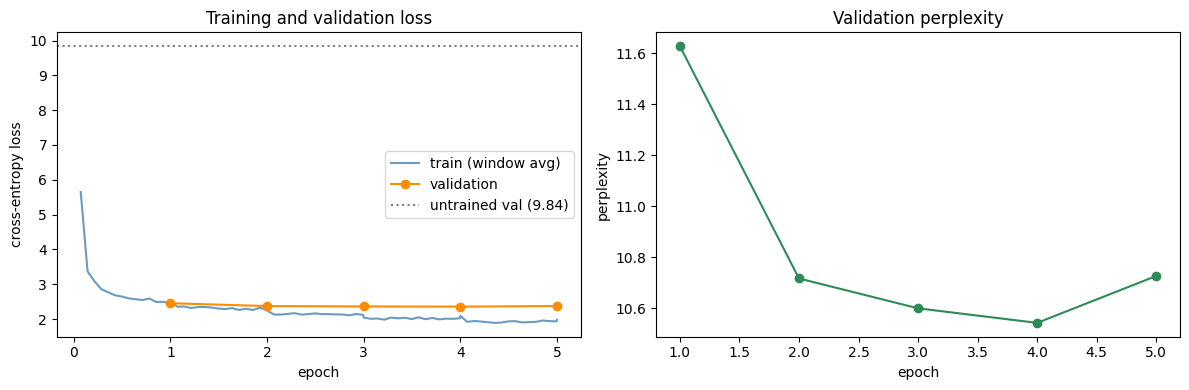

,reference,epoch 0,epoch 1,epoch 2,epoch 3,epoch 4,epoch 5
img 149,a fully stocked refrigerator with the door wide open,"be a ""t-1-in-the-game"" (t-1-in-the-game) for the first time.",a refrigerator with a bunch of food on it,a refrigerator with a bunch of food in it,a refrigerator with a bunch of different foods on it,a refrigerator with a bunch of different foods in it,a refrigerator with a bunch of different foods in it
img 599,large group of people sitting in a room working on their computers,"(1) the ""A-1-1-1-1-1-1-1-1-1-1-1-1",a group of people are sitting at a table with laptops,a group of people are standing around a conference room,a group of people standing around a large conference room,a group of people standing around a conference room,a group of people standing around a conference room
img 1293,an extremely large hamburger with a salad and fried on a table,"(1) the ""A-1-1-1-1-1-1-1-1-1-1-1-1",a plate of food with a sandwich and a drink,a sandwich with fries and a glass of wine,a sandwich and a drink on a table,a sandwich and a drink on a plate,a sandwich and a drink sit on a plate
img 1670,a bunch of people walk along with an elephant on a street,be the first-in-name-of-the-name-of-the-name-of-the-name-of-the-,a group of people walking down a street with elephants,a group of people walking around a large elephant,a group of people walking down a street,a group of people walking down a street with a bunch of people riding on the...,a group of people walking down a street with elephants
img 2223,a group of people getting on to a bus,"(1) the ""M-1-1-1-1-1-1-1-1-1-1-1-1",a bus is parked in front of a building,a group of people on a bus in a city,a group of people riding on top of a bus,a group of people on a bus in a city,a group of people on a city street
img 3382,two dogs stand in a kitchen beneath their owner,"be a ""t-1-in-the-game"" (t-1-in-the-game) (t-1-in",a dog is sitting on a kitchen counter next to a refrigerator,a dog and a cat are standing in a kitchen,two dogs standing in front of a kitchen counter,two dogs standing in a kitchen doorway,two dogs standing in a kitchen doorway looking at the kitchen counter
img 3773,a person is playing a tennis game by himself,"(1) the ""M-1-1-1-1-1-1-1-1-1-1-1-1",a man is standing on a tennis court with a tennis racket,a woman is holding a tennis racket in her hand,a woman is playing tennis on a tennis court,a woman is playing tennis on a tennis court,a woman is playing tennis on a tennis court
img 4866,two woman holding tennis rackets posing for a photo,(1) the first-in-name-of-a-name-of-a-name-of-a-name-of-,two women holding tennis racquets,two women holding tennis racquets in a row,two women standing on top of a tennis court,two women are playing tennis on a court,two women standing on top of a tennis court holding tennis racquets


In [12]:
# Loss curves
LOSS_PLOT = os.path.join(OUT_DIR, "loss_curve.png")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
steps_per_epoch = len(train_loader)
ax[0].plot(step_df["global_step"] / steps_per_epoch, step_df["train_loss"], color="steelblue", alpha=0.8, label="train (window avg)")
tr = epoch_df[epoch_df.epoch > 0]
ax[0].plot(tr["epoch"], tr["val_loss"], "o-", color="darkorange", label="validation")
ax[0].axhline(base_val, color="gray", ls=":", label=f"untrained val ({base_val:.2f})")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Training and validation loss"); ax[0].legend()
ax[1].plot(tr["epoch"], tr["val_ppl"], "o-", color="seagreen")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("perplexity"); ax[1].set_title("Validation perplexity")
plt.tight_layout(); plt.savefig(LOSS_PLOT, dpi=150); plt.show()

# Caption evolution on the sample images (greedy)
evolution_df = pd.DataFrame({f"epoch {e}": [caption_history[e][i] for i in SAMPLE_IDS] for e in sorted(caption_history)},
                            index=[f"img {i}" for i in SAMPLE_IDS])
evolution_df.insert(0, "reference", [image_to_captions[i][0] for i in SAMPLE_IDS])
pd.set_option("display.max_colwidth", 80)
evolution_df

## 10. Early Caption Samples: All Decoding Strategies on the Sample Images

EARLY CAPTION SAMPLES (best checkpoint)
[img 149] REF: a fully stocked refrigerator with the door wide open
    Greedy                   a refrigerator with a bunch of different foods in it
    Beam (k=3)               a refrigerator filled with lots of fresh produce
    Beam (k=5)               a refrigerator with a bunch of different foods in it
    Nucleus (p=0.9, T=0.7)   a refrigerator filled with fresh vegetables and other foods
    Nucleus (p=0.9, T=1.0)   a refrigerator in a long, white refrigerator
[img 599] REF: large group of people sitting in a room working on their computers
    Greedy                   a group of people standing around a conference room
    Beam (k=3)               a large group of people in a conference room
    Beam (k=5)               a large group of people in a conference room
    Nucleus (p=0.9, T=0.7)   a lot of people are gathered around a table
    Nucleus (p=0.9, T=1.0)   a crowded lot of people gathered around a video game event
[img 1293] REF:

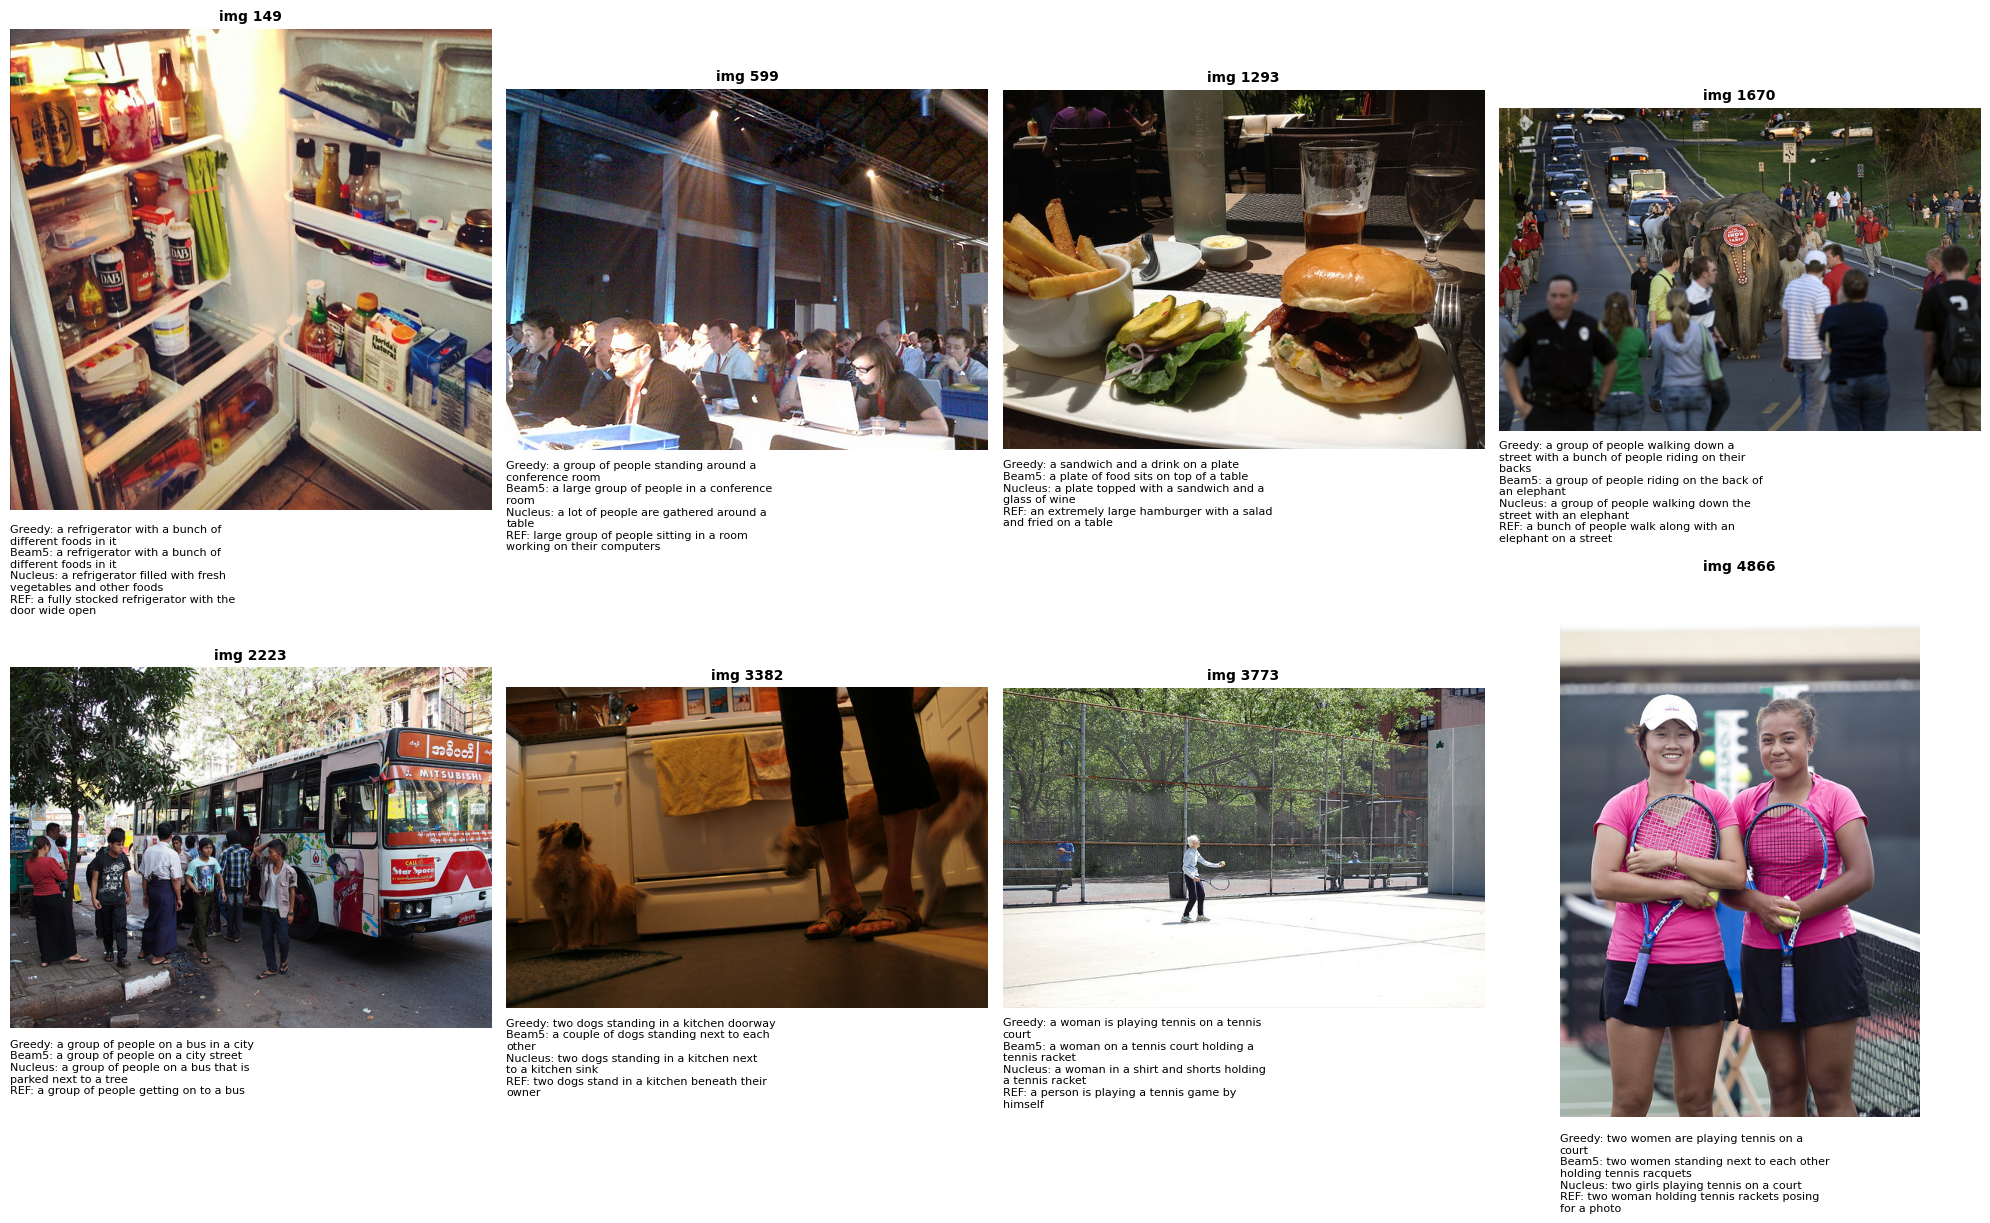

,image_id,reference,Greedy,Beam (k=3),Beam (k=5),"Nucleus (p=0.9, T=0.7)","Nucleus (p=0.9, T=1.0)"
0,149,a fully stocked refrigerator with the door wide open,a refrigerator with a bunch of different foods in it,a refrigerator filled with lots of fresh produce,a refrigerator with a bunch of different foods in it,a refrigerator filled with fresh vegetables and other foods,"a refrigerator in a long, white refrigerator"
1,599,large group of people sitting in a room working on their computers,a group of people standing around a conference room,a large group of people in a conference room,a large group of people in a conference room,a lot of people are gathered around a table,a crowded lot of people gathered around a video game event
2,1293,an extremely large hamburger with a salad and fried on a table,a sandwich and a drink on a plate,a plate of food on a table with a glass of beer,a plate of food sits on top of a table,a plate topped with a sandwich and a glass of wine,a plate topped with a roast beef sandwich with fries on a bun
3,1670,a bunch of people walk along with an elephant on a street,a group of people walking down a street with a bunch of people riding on the...,a group of people riding on the back of an elephant,a group of people riding on the back of an elephant,a group of people walking down the street with an elephant,a parade of people walk down the road
4,2223,a group of people getting on to a bus,a group of people on a bus in a city,a group of people on a city street,a group of people on a city street,a group of people on a bus that is parked next to a tree,a group of people on a city street
5,3382,two dogs stand in a kitchen beneath their owner,two dogs standing in a kitchen doorway,a couple of dogs standing in a kitchen,a couple of dogs standing next to each other,two dogs standing in a kitchen next to a kitchen sink,two dogs wait at the kitchen sink while a person walks in the doorway
6,3773,a person is playing a tennis game by himself,a woman is playing tennis on a tennis court,a woman on a tennis court holding a tennis racket,a woman on a tennis court holding a tennis racket,a woman in a shirt and shorts holding a tennis racket,a woman swings a tennis racket at the bat
7,4866,two woman holding tennis rackets posing for a photo,two women are playing tennis on a court,two girls are playing tennis on a court,two women standing next to each other holding tennis racquets,two girls playing tennis on a court,two young girls on a tennis court with a racket


In [13]:
sample_results, sample_times = {}, {}
for name, fn in STRATEGIES.items():
    t0 = time.time()
    sample_results[name] = fn(model, sample_embs)
    sample_times[name] = (time.time() - t0) / len(SAMPLE_IDS) * 1000

sample_df = pd.DataFrame({"image_id": SAMPLE_IDS, "reference": [image_to_captions[i][0] for i in SAMPLE_IDS]})
for name in STRATEGIES:
    sample_df[name] = sample_results[name]
sample_df.to_csv(os.path.join(OUT_DIR, "sample_captions.csv"), index=False)

log("=" * 90)
log("EARLY CAPTION SAMPLES (best checkpoint)")
for k, i in enumerate(SAMPLE_IDS):
    log(f"[img {i}] REF: {image_to_captions[i][0]}")
    for name in STRATEGIES:
        log(f"    {name:24s} {sample_results[name][k]}")
log("=" * 90)

GRID_PLOT = os.path.join(OUT_DIR, "sample_captions_grid.png")
n = len(SAMPLE_IDS); cols = 4; rows = math.ceil(n / cols)
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 6.2 * rows))
for ax, k in zip(np.array(axes).reshape(-1), range(rows * cols)):
    ax.axis("off")
    if k >= n:
        continue
    i = SAMPLE_IDS[k]
    if sample_images[i] is not None:
        ax.imshow(sample_images[i])
    text = "\n".join(textwrap.fill(f"{lab}: {sample_results[s][k]}", 46) for lab, s in
                     [("Greedy", "Greedy"), ("Beam5", "Beam (k=5)"), ("Nucleus", "Nucleus (p=0.9, T=0.7)")])
    text += "\n" + textwrap.fill(f"REF: {image_to_captions[i][0]}", 46)
    ax.set_title(f"img {i}", fontsize=10, fontweight="bold")
    ax.text(0, -0.03, text, transform=ax.transAxes, fontsize=8, va="top")
plt.tight_layout(); plt.savefig(GRID_PLOT, dpi=130, bbox_inches="tight"); plt.show()
sample_df